# How good are the forecasts, and how fast should we discount future weeks

Forecasts for the current gameweek and the eight after it (leads 1 to 9), for every player and gameweek, scored against realized points. The slope of realized points on the forecast, over the top 150 players by forecast, says how much of a forecast to believe, and the `hKb` strategies use these slopes as weights for week $k$ of a plan.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import data, model, sim, bank, milp
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6, 'font.size': 9})
os.makedirs('figs', exist_ok=True)
save = lambda fig, nm: [fig.savefig(f'figs/{nm}.{ext}', bbox_inches='tight') for ext in ['pdf', 'png']]

In [2]:
cal = pd.read_csv('data/cache/calib.csv')
num = cal[cal.k.astype(str).str.isdigit()].astype({'k': int})
num.groupby('k')[['rmse', 'corr', 'beta', 'mean_x', 'mean_y']].mean().round(3)

,rmse,corr,beta,mean_x,mean_y
k,,,,,
1,2.062,0.512,1.020,3.060,3.143
2,2.078,0.499,1.010,3.064,3.078
3,2.095,0.490,0.978,3.067,3.045
4,2.104,0.484,0.956,3.073,3.019
5,2.119,0.477,0.924,3.077,2.994
6,2.130,0.472,0.917,3.083,2.973
7,2.141,0.467,0.913,3.086,2.950
8,2.150,0.463,0.902,3.095,2.939
9,2.154,0.459,0.873,3.101,2.929


Slope about 1 one week ahead (the forecasts are calibrated on the players the squad-picker sees), then a slow decline. Practitioners weight future weeks by 0.85 per week, which is far steeper.

/var/folders/gb/h7f_p2456czc0nzttyn761dm0000gn/T/ipykernel_2691/1337187333.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  m = rel.mean(1)


season,2021-22,2022-23,2023-24,2024-25,2025-26
k,,,,,
1,1.000,1.000,1.000,1.000,1.000
2,0.969,0.988,1.012,1.013,0.964
3,0.951,0.991,0.995,0.942,0.913
4,0.956,0.917,0.961,0.934,0.914
5,0.924,0.946,0.926,0.866,0.874
6,0.952,0.966,0.875,0.844,0.867
7,0.955,0.960,0.824,0.892,0.843
8,0.913,0.927,0.825,0.907,0.846
9,0.900,0.904,0.762,0.890,0.820


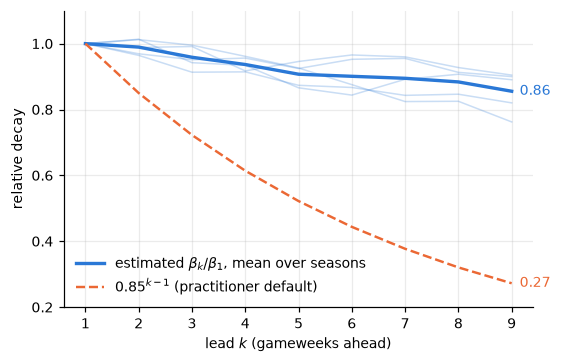

In [3]:
b = num.groupby(['season', 'k']).beta.mean().unstack(0)
rel = b / b.loc[1]
m = rel.mean(1)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for s in rel.columns:
    ax.plot(rel.index, rel[s], color=C[0], alpha=0.25, lw=1)
ax.plot(m.index, m, color=C[0], lw=2.2, label='estimated $\\beta_k/\\beta_1$, mean over seasons')
ax.plot(m.index, 0.85 ** (m.index - 1), color=C[1], ls='--', label='$0.85^{k-1}$ (practitioner default)')
ax.text(m.index[-1] + 0.15, m.iloc[-1], f'{m.iloc[-1]:.2f}', va='center', color=C[0])
ax.text(m.index[-1] + 0.15, 0.85 ** (m.index[-1] - 1), f'{0.85 ** (m.index[-1] - 1):.2f}', va='center', color=C[1])
ax.set_xlabel('lead $k$ (gameweeks ahead)'); ax.set_ylabel('relative decay'); ax.set_ylim(0.2, 1.1)
ax.legend(frameon=False, loc='lower left')
save(fig, 'decay')
rel.round(3)

[None, None]

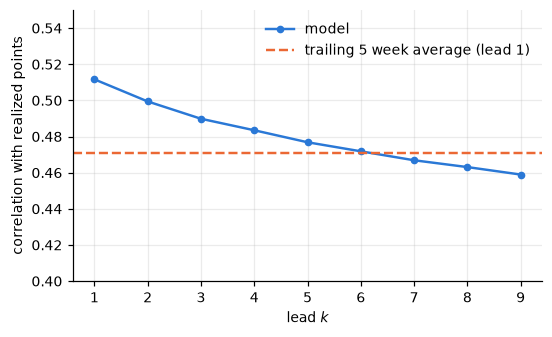

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
c = num.groupby('k')['corr'].mean()
ax.plot(c.index, c, color=C[0], marker='o', ms=4, label='model')
tr = cal[cal.k == 'trail']['corr'].mean()
ax.axhline(tr, color=C[1], ls='--', label='trailing 5 week average (lead 1)')
ax.set_xlabel('lead $k$'); ax.set_ylabel('correlation with realized points'); ax.set_ylim(0.4, 0.55); ax.legend(frameon=False)
save(fig, 'corr_by_lead')

## The archived `xP` column contains the results

The archive stores the site's expected points, scraped after the gameweek. A forecast made before the deadline of week $t$ should predict week $t+1$ nearly as well as it predicts week $t$ (the model does). The site column collapses from one week to the next, so it carries the week's own results and cannot be used as a forecast. The `site1` and `site3` strategies in the backtest are kept only to show how large the leak is.

In [5]:
rows = []
for s in data.SEASONS:
    p, *_ = model.bundle(s); fc = model.forecasts(s)
    real, site = data.wide(p, 'pts'), data.wide(p, 'xP')
    for t in range(2, 38):
        xp = fc[t][0]; idx = xp.index
        d = pd.DataFrame(dict(x=site[t].reindex(idx), y0=real[t].reindex(idx), y1=real[t + 1].reindex(idx),
                              m0=xp[t], m1=xp[t + 1])).fillna(0)
        rows.append(dict(season=s, site_same=d.x.corr(d.y0), site_next=d.x.corr(d.y1), model_same=d.m0.corr(d.y0), model_next=d.m1.corr(d.y1)))
pd.DataFrame(rows).groupby('season').mean().round(3)

/Users/benjamindrouet/Projects/fpl-mdp/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/benjamindrouet/Projects/fpl-mdp/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/Users/benjamindrouet/Projects/fpl-mdp/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/benjamindrouet/Projects/fpl-mdp/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/Users/benjamindrouet/Projects/fpl-mdp/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/benjamindrouet/Projects/fpl-mdp/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/Users/benjamindrouet/Projects/fpl-mdp/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/benjamindrouet/Projects/fpl-mdp/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,site_same,site_next,model_same,model_next
season,,,,
2021-22,0.720,0.375,0.519,0.507
2022-23,0.738,0.423,0.505,0.493
2023-24,0.732,0.432,0.505,0.492
2024-25,0.726,0.456,0.516,0.502
2025-26,0.766,0.495,0.513,0.503
